In [48]:
import numpy as np
import cupy as cp
import time
import cv2
import matplotlib.pyplot as plt

print("NumPy :", np.__version__)
print("CuPy  :", cp.__version__)

NumPy : 2.1.3
CuPy  : 14.0.1


In [49]:
# IMAGE_PATH = "src/images/seagull.jpg"
IMAGE_PATH = "seagull.jpg"

TARGET_WIDTH = 1280
TARGET_HEIGHT = 720

TRAIL_LENGTH = 32

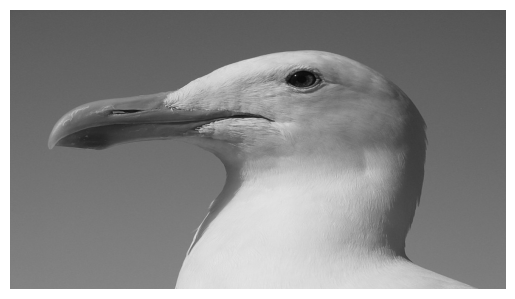

In [50]:
img_gray = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)

if img_gray is None:
    raise FileNotFoundError(f"이미지를 읽을 수 없습니다: {IMAGE_PATH}")

img_gray = cv2.resize(
    img_gray,
    (TARGET_WIDTH, TARGET_HEIGHT),
    interpolation=cv2.INTER_AREA
)

input_np = img_gray.astype(np.float32) / 255.0

plt.imshow(input_np, cmap="gray")
plt.axis("off");

In [51]:
# TODO: NumPy를 사용하여 잔상 효과 함수 정의

def motion_trail_np(image, weights):
    """
    NumPy를 이용해 이미지 잔상 효과를 생성한다.

    출력 픽셀을 Python 반복문으로 하나씩 계산한다.
    """

    # TODO: 필요한 변수 정의 및 출력 배열 생성
    output = np.zeros((TARGET_HEIGHT, TARGET_WIDTH), dtype=np.float32)
    pixel_idx = 0

    for output_y in output:
        for output_x in output_y:

            for shift in range(TRAIL_LENGTH):
                # TODO: x값 shift
                y, x = divmod(pixel_idx, TARGET_WIDTH)
                input_x = x - shift
                # TODO: shift한 픽셀을 누적
                if input_x >= 0:
                  output[y, x] += image[y, input_x] * weights[shift]
                # TODO: 출력 배열에 누적 픽셀 저장
                if shift == TRAIL_LENGTH - 1:
                  pixel_idx += 1

    return output

In [52]:
# TODO: CuPy를 사용하여 잔상 효과 함수 정의

def motion_trail_cp(image, weights):
    """
    CuPy를 이용해 이미지 잔상 효과를 생성한다.

    이동 거리는 Python에서 순차적으로 반복하지만,
    각 이동 거리의 이미지 전체 계산은 GPU에서 병렬 처리한다.
    """

    # TODO: 필요한 변수 정의 및 출력 배열 생성
    width = image.shape[1]
    output = cp.zeros_like(image, dtype=cp.float32)

    for shift in range(TRAIL_LENGTH):
        # TODO: 배열 slicing
        input_region = image[:, :width - shift]
        output_region = output[:, shift:]

        # TODO: GPU가 병렬 연산할 output_region 계산 코드
        if shift < len(weights):
          output_region += input_region * weights[shift]
    return output

In [53]:
# 이동 거리가 멀어질수록 가중치를 작게 설정
weights_np = np.linspace(
    1.0,
    0.05,
    TRAIL_LENGTH,
    dtype=np.float32
)

# 전체 가중치의 합을 1로 정규화
weights_np /= np.sum(weights_np)

In [54]:
cpu_start = time.perf_counter()

output_np = motion_trail_np(
    image=input_np,
    weights=weights_np
)

cpu_end = time.perf_counter()

cpu_time = cpu_end - cpu_start

In [55]:
# TODO: NumPy 배열을 CuPy 배열로 변환

upload_start = time.perf_counter()

input_cp = cp.asarray(input_np)
weights_cp = cp.asarray(weights_np)

cp.cuda.Stream.null.synchronize()

upload_end = time.perf_counter()

upload_time = upload_end - upload_start

In [57]:
warmup_image = cp.zeros((64, 64), dtype=cp.float32)
warmup_weights = cp.asarray(weights_np[:4])

_ = motion_trail_cp(
    image=warmup_image,
    weights=warmup_weights
)

cp.cuda.Stream.null.synchronize()

In [58]:
cp.cuda.Stream.null.synchronize()

gpu_start = time.perf_counter()

output_cp = motion_trail_cp(
    image=input_cp,
    weights=weights_cp
)

cp.cuda.Stream.null.synchronize()

gpu_end = time.perf_counter()

gpu_time = gpu_end - gpu_start

In [59]:
# TODO: output_cp를 CPU 메모리로 복사

download_start = time.perf_counter()

output_cp_np = cp.asnumpy(output_cp)

download_end = time.perf_counter()

download_time = download_end - download_start

In [60]:
compute_speedup = cpu_time / gpu_time

gpu_total_time = upload_time + gpu_time + download_time
total_speedup = cpu_time / gpu_total_time

In [61]:
print("========== NumPy CPU ==========")
print(f"Processing time: {cpu_time:.4f} seconds")
print()

print("========== CuPy GPU ==========")
print(f"CPU to GPU: {upload_time:.4f} seconds")
print(f"GPU processing: {gpu_time:.4f} seconds")
print(f"GPU to CPU: {download_time:.4f} seconds")
print(f"Total GPU time: {gpu_total_time:.4f} seconds")
print()

print("========== Comparison ==========")
print(f"Compute-only speedup: {compute_speedup:.2f}x")
print(f"Including transfers: {total_speedup:.2f}x")

========== NumPy CPU ==========
Processing time: 19.6618 seconds

========== CuPy GPU ==========
CPU to GPU: 0.0024 seconds
GPU processing: 0.0042 seconds
GPU to CPU: 0.0016 seconds
Total GPU time: 0.0082 seconds

========== Comparison ==========
Compute-only speedup: 4689.48x
Including transfers: 2401.57x


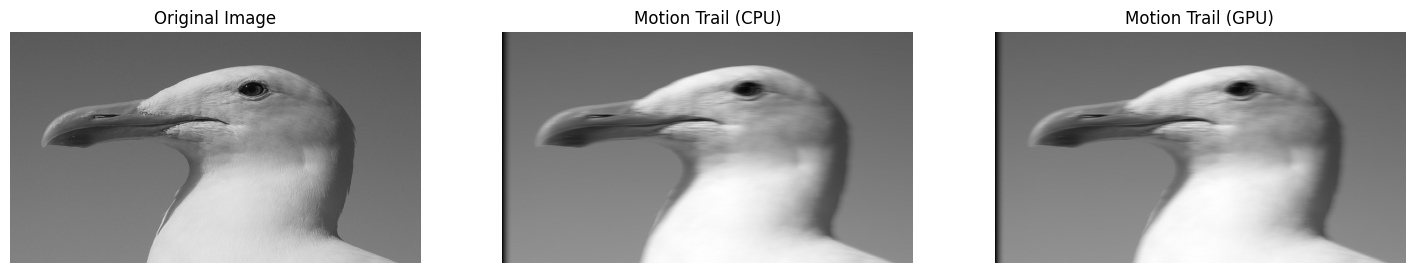

In [62]:
plt.figure(figsize=(18,12))

plt.subplot(1,3,1), plt.imshow(input_np, cmap="gray"), plt.title("Original Image")
plt.subplot(1,3,2), plt.imshow(output_np, cmap="gray"), plt.title("Motion Trail (CPU)")
plt.subplot(1,3,3), plt.imshow(output_cp_np, cmap="gray"), plt.title("Motion Trail (GPU)")

for ax in plt.gcf().axes:
    ax.axis("off")

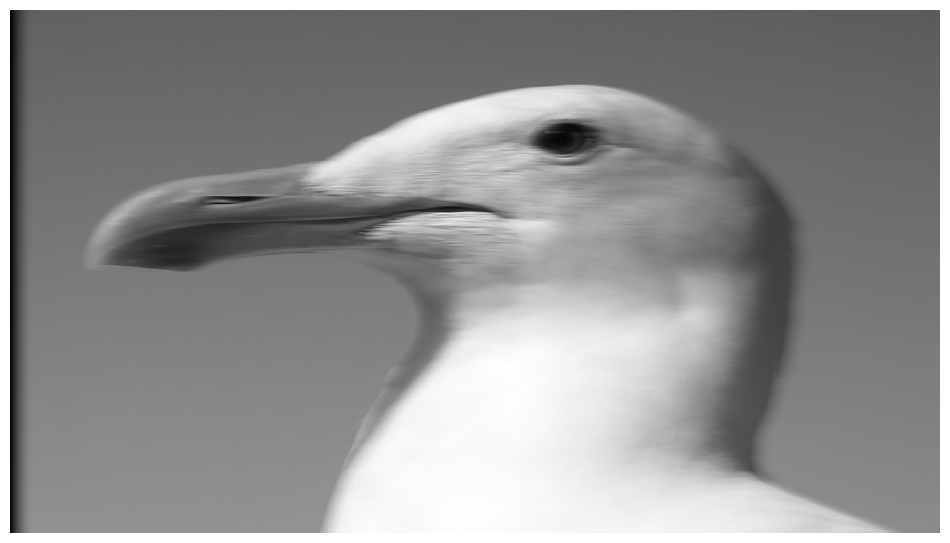

In [63]:
plt.figure(figsize=(12,8))
plt.imshow(output_cp_np, cmap="gray")
plt.axis("off");